In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import json

# Dataset preparation
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# CELL 2: LOAD IRIS DATASET

iris = load_iris()

X_raw = iris.data
y_raw = iris.target

feature_names = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

class_names = iris.target_names

# Display the dataset
df = pd.DataFrame(X_raw, columns=feature_names)

df["class_id"] = y_raw
df["class_name"] = [class_names[i] for i in y_raw]

print("Dataset loaded successfully!")
print("Number of samples:", len(X_raw))
print("Number of features:", X_raw.shape[1])
print("Number of classes:", len(class_names))

display(df.head(10))

print("\nClass distribution:")
print(df["class_name"].value_counts())



Dataset loaded successfully!
Number of samples: 150
Number of features: 4
Number of classes: 3


,sepal_length,sepal_width,petal_length,petal_width,class_id,class_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa
8,4.4,2.9,1.4,0.2,0,setosa
9,4.9,3.1,1.5,0.1,0,setosa



Class distribution:
class_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:

# CELL 3: SPLIT DATASET

sample_ids = np.arange(len(X_raw))

# First split: 70% training, 30% temporary
train_ids, temp_ids = train_test_split(
    sample_ids,
    test_size=0.30,
    random_state=42,
    stratify=y_raw
)

# Second split: divide temporary data into validation and test
val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42,
    stratify=y_raw[temp_ids]
)

X_train_raw = X_raw[train_ids]
y_train = y_raw[train_ids]

X_val_raw = X_raw[val_ids]
y_val = y_raw[val_ids]

X_test_raw = X_raw[test_ids]
y_test = y_raw[test_ids]

print("Training samples:", len(X_train_raw))
print("Validation samples:", len(X_val_raw))
print("Testing samples:", len(X_test_raw))


Training samples: 105
Validation samples: 22
Testing samples: 23


In [ ]:

# CELL 4: STANDARDISE INPUT FEATURES

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("Standardisation completed!")

print("\nTraining feature means:")
print(np.round(X_train.mean(axis=0), 4))

print("\nTraining feature standard deviations:")
print(np.round(X_train.std(axis=0), 4))

print("\nFinal data shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


Standardisation completed!

Training feature means:
[ 0. -0. -0. -0.]

Training feature standard deviations:
[1. 1. 1. 1.]

Final data shapes:
X_train: (105, 4)
X_val: (22, 4)
X_test: (23, 4)


In [ ]:

# CELL 5: DEFINE HPO CONFIGURATIONS

hpo_configs = [
    {"run_id": 1, "learning_rate": 0.001, "batch_size": 16, "hidden_units": 8, "optimizer": "SGD"},
    {"run_id": 2, "learning_rate": 0.003, "batch_size": 16, "hidden_units": 8, "optimizer": "SGD"},
    {"run_id": 3, "learning_rate": 0.01,  "batch_size": 16, "hidden_units": 8, "optimizer": "SGD"},
    {"run_id": 4, "learning_rate": 0.03,  "batch_size": 16, "hidden_units": 8, "optimizer": "SGD"},
    {"run_id": 5, "learning_rate": 0.1,   "batch_size": 16, "hidden_units": 8, "optimizer": "SGD"},
    {"run_id": 6, "learning_rate": 0.01,  "batch_size": 8,  "hidden_units": 8, "optimizer": "SGD"},
    {"run_id": 7, "learning_rate": 0.01,  "batch_size": 32, "hidden_units": 8, "optimizer": "SGD"},
    {"run_id": 8, "learning_rate": 0.01,  "batch_size": 16, "hidden_units": 4, "optimizer": "SGD"},
    {"run_id": 9, "learning_rate": 0.01,  "batch_size": 16, "hidden_units": 16, "optimizer": "SGD"},
    {"run_id": 10, "learning_rate": 0.03, "batch_size": 32, "hidden_units": 16, "optimizer": "SGD"}
]

config_df = pd.DataFrame(hpo_configs)

display(config_df)

print("Total HPO runs:", len(hpo_configs))


,run_id,learning_rate,batch_size,hidden_units,optimizer
0,1,0.001,16,8,SGD
1,2,0.003,16,8,SGD
2,3,0.010,16,8,SGD
3,4,0.030,16,8,SGD
4,5,0.100,16,8,SGD
5,6,0.010,8,8,SGD
6,7,0.010,32,8,SGD
7,8,0.010,16,4,SGD
8,9,0.010,16,16,SGD
9,10,0.030,32,16,SGD


Total HPO runs: 10


In [ ]:

# CELL 6: ANN FUNCTIONS FROM SCRATCH

def initialise_parameters(input_units, hidden_units, output_units, seed=42):

    rng = np.random.default_rng(seed)

    # He initialisation for weights
    W1 = rng.normal(
        0, np.sqrt(2 / input_units),
        size=(input_units, hidden_units)
    )

    W2 = rng.normal(
        0, np.sqrt(2 / hidden_units),
        size=(hidden_units, output_units)
    )

    b1 = np.zeros((1, hidden_units))
    b2 = np.zeros((1, output_units))

    return {
        "W1": W1,
        "b1": b1,
        "W2": W2,
        "b2": b2
    }


def relu(z):
    return np.maximum(0, z)


def softmax(z):

    # Numerical stability
    z = z - np.max(z, axis=1, keepdims=True)

    exp_z = np.exp(z)

    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def forward_propagation(X, params):

    W1 = params["W1"]
    b1 = params["b1"]
    W2 = params["W2"]
    b2 = params["b2"]

    # Hidden layer
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # Output layer
    Z2 = A1 @ W2 + b2

    # Output probabilities
    probabilities = softmax(Z2)

    cache = {
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "probabilities": probabilities
    }

    return probabilities, cache


def cross_entropy_loss(probabilities, y):

    n = len(y)

    correct_probabilities = probabilities[
        np.arange(n), y
    ]

    losses = -np.log(
        np.clip(correct_probabilities, 1e-12, 1.0)
    )

    return np.mean(losses), losses


def backpropagation(X, y, params, cache):

    m = len(X)

    W2 = params["W2"]

    A1 = cache["A1"]
    probabilities = cache["probabilities"]
    Z1 = cache["Z1"]

    # One-hot encoding
    Y = np.zeros_like(probabilities)
    Y[np.arange(m), y] = 1

    # Output layer gradients
    dZ2 = (probabilities - Y) / m

    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer gradients
    dA1 = dZ2 @ W2.T

    # ReLU derivative
    dZ1 = dA1 * (Z1 > 0)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2
    }

    return gradients


def calculate_norm(arrays):

    return np.sqrt(
        sum(np.sum(array ** 2) for array in arrays)
    )


def calculate_metrics(X, y, params):

    probabilities, cache = forward_propagation(X, params)

    loss, sample_losses = cross_entropy_loss(
        probabilities, y
    )

    predictions = np.argmax(probabilities, axis=1)

    metrics = {
        "loss": loss,
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(
            y, predictions, average="macro", zero_division=0
        ),
        "recall": recall_score(
            y, predictions, average="macro", zero_division=0
        ),
        "f1": f1_score(
            y, predictions, average="macro", zero_division=0
        )
    }

    return metrics, probabilities, cache, sample_losses


print("ANN mathematical functions defined successfully!")


ANN mathematical functions defined successfully!


In [ ]:

# CELL 7: TEST ANN FORWARD AND BACKPROPAGATION

test_params = initialise_parameters(
    input_units=4,
    hidden_units=8,
    output_units=3,
    seed=42
)

# Use a small batch
X_demo = X_train[:5]
y_demo = y_train[:5]

# Forward propagation
demo_probabilities, demo_cache = forward_propagation(
    X_demo, test_params
)

# Loss
demo_loss, demo_sample_losses = cross_entropy_loss(
    demo_probabilities, y_demo
)

# Backpropagation
demo_gradients = backpropagation(
    X_demo, y_demo, test_params, demo_cache
)

print("Prediction probabilities:")
print(np.round(demo_probabilities, 4))

print("\nProbability sums:")
print(demo_probabilities.sum(axis=1))

print("\nInitial loss:", demo_loss)

print("\nGradient shapes:")
for name, value in demo_gradients.items():
    print(name, value.shape)

print("\nANN test completed!")


Prediction probabilities:
[[0.633  0.2136 0.1534]
 [0.4667 0.3366 0.1967]
 [0.3827 0.4047 0.2126]
 [0.1992 0.755  0.0458]
 [0.4015 0.3296 0.2688]]

Probability sums:
[1. 1. 1. 1. 1.]

Initial loss: 1.5574497822812063

Gradient shapes:
W1 (4, 8)
b1 (1, 8)
W2 (8, 3)
b2 (1, 3)

ANN test completed!


In [ ]:

# CELL 8: INTERNAL STATE RECORDING FUNCTIONS

# Store parameter information in a readable format
def flatten_parameters(params):

    flattened = {}

    for parameter_name, array in params.items():

        for index in np.ndindex(array.shape):

            name = parameter_name + "_" + "_".join(
                map(str, index)
            )

            flattened[name] = float(array[index])

    return flattened


def record_parameter_updates(
    run_id, epoch, batch_id, params_before,
    gradients, params_after, learning_rate
):

    records = []

    for parameter_name in params_before:

        before = params_before[parameter_name]
        gradient = gradients[parameter_name]
        after = params_after[parameter_name]

        for index in np.ndindex(before.shape):

            records.append({
                "run_id": run_id,
                "epoch": epoch,
                "batch_id": batch_id,
                "parameter_name": parameter_name,
                "parameter_index": str(index),
                "value_before": float(before[index]),
                "gradient": float(gradient[index]),
                "learning_rate": learning_rate,
                "parameter_change": float(
                    after[index] - before[index]
                ),
                "value_after": float(after[index])
            })

    return records


def record_parameter_snapshot(
    run_id, epoch, params, phase="epoch_end"
):

    records = []

    for parameter_name, array in params.items():

        for index in np.ndindex(array.shape):

            records.append({
                "run_id": run_id,
                "epoch": epoch,
                "phase": phase,
                "parameter_name": parameter_name,
                "parameter_index": str(index),
                "value": float(array[index])
            })

    return records


def record_sample_states(
    run_id, epoch, split_name, X, y, sample_ids, params
):

    probabilities, cache = forward_propagation(X, params)

    _, sample_losses = cross_entropy_loss(
        probabilities, y
    )

    predictions = np.argmax(probabilities, axis=1)

    records = []

    for i in range(len(X)):

        row = {
            "run_id": run_id,
            "epoch": epoch,
            "split": split_name,
            "sample_id": int(sample_ids[i]),

            "true_class_id": int(y[i]),
            "true_class": class_names[y[i]],

            "predicted_class_id": int(predictions[i]),
            "predicted_class": class_names[predictions[i]],

            "sample_loss": float(sample_losses[i])
        }

        # Original scaled input features
        for j, name in enumerate(feature_names):
            row["input_" + name] = float(X[i, j])

        # Hidden-layer weighted sums
        for j, value in enumerate(cache["Z1"][i]):
            row[f"hidden_z_{j+1}"] = float(value)

        # Hidden-layer activations
        for j, value in enumerate(cache["A1"][i]):
            row[f"hidden_activation_{j+1}"] = float(value)

        # Output logits
        for j, value in enumerate(cache["Z2"][i]):
            row[f"output_logit_{j+1}"] = float(value)

        # Output probabilities
        for j, value in enumerate(probabilities[i]):
            row[f"output_probability_{j+1}"] = float(value)

        records.append(row)

    return records


print("Internal-state recording functions created!")


Internal-state recording functions created!


In [ ]:

# CELL 9: TRAIN ONE HPO RUN AND RECORD ITS STATES

def train_one_run(config, epochs=50, seed=42):

    run_id = config["run_id"]
    learning_rate = config["learning_rate"]
    batch_size = config["batch_size"]
    hidden_units = config["hidden_units"]

    # Initialise a separate ANN for this run
    params = initialise_parameters(
        input_units=4,
        hidden_units=hidden_units,
        output_units=3,
        seed=seed
    )

    # Separate random generator for batch shuffling
    shuffle_rng = np.random.default_rng(2025)

    # Recording containers
    epoch_records = []
    sample_records = []
    update_records = []
    snapshot_records = []

    # Record initial parameter values
    snapshot_records.extend(
        record_parameter_snapshot(
            run_id, 0, params, phase="initial"
        )
    )

    for epoch in range(1, epochs + 1):

        epoch_gradient_norms = []
        epoch_update_norms = []

        # Shuffle training samples
        order = shuffle_rng.permutation(len(X_train))

        X_shuffled = X_train[order]
        y_shuffled = y_train[order]

        # Mini-batch training
        batch_id = 0

        for start in range(0, len(X_train), batch_size):

            batch_id += 1

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Forward propagation
            probabilities, cache = forward_propagation(
                X_batch, params
            )

            # Backpropagation
            gradients = backpropagation(
                X_batch, y_batch, params, cache
            )

            # Record gradients before updating parameters
            gradient_norm = calculate_norm(
                list(gradients.values())
            )

            # Preserve parameter values before update
            params_before = {
                name: value.copy()
                for name, value in params.items()
            }

            # Gradient Descent
            for name in params:

                params[name] -= (
                    learning_rate * gradients[name]
                )

            # Calculate parameter changes
            update_norm = calculate_norm([
                params[name] - params_before[name]
                for name in params
            ])

            epoch_gradient_norms.append(gradient_norm)
            epoch_update_norms.append(update_norm)

            # Record every parameter update
            update_records.extend(
                record_parameter_updates(
                    run_id,
                    epoch,
                    batch_id,
                    params_before,
                    gradients,
                    params,
                    learning_rate
                )
            )

        # Evaluate after completing this epoch
        train_metrics, _, _, _ = calculate_metrics(
            X_train, y_train, params
        )

        val_metrics, _, _, _ = calculate_metrics(
            X_val, y_val, params
        )

        # Weight and bias statistics
        weights = np.concatenate([
            params["W1"].flatten(),
            params["W2"].flatten()
        ])

        biases = np.concatenate([
            params["b1"].flatten(),
            params["b2"].flatten()
        ])

        epoch_records.append({

            "run_id": run_id,
            "epoch": epoch,

            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],

            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],

            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],

            "weight_mean": np.mean(weights),
            "weight_std": np.std(weights),
            "weight_norm": np.linalg.norm(weights),

            "bias_mean": np.mean(biases),
            "bias_std": np.std(biases),

            "gradient_norm_mean": np.mean(
                epoch_gradient_norms
            ),

            "gradient_norm_std": np.std(
                epoch_gradient_norms
            ),

            "update_norm_mean": np.mean(
                epoch_update_norms
            )
        })

        # Save complete parameter snapshot
        snapshot_records.extend(
            record_parameter_snapshot(
                run_id, epoch, params
            )
        )

        # Record training sample states after this epoch
        sample_records.extend(
            record_sample_states(
                run_id, epoch, "train",
                X_train, y_train, train_ids, params
            )
        )

        # Record validation sample states after this epoch
        sample_records.extend(
            record_sample_states(
                run_id, epoch, "validation",
                X_val, y_val, val_ids, params
            )
        )

        print(
            f"Run {run_id:02d} | Epoch {epoch:02d} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Accuracy: {val_metrics['accuracy']:.4f}"
        )

    return {
        "params": {
            name: value.copy()
            for name, value in params.items()
        },
        "epoch_records": epoch_records,
        "sample_records": sample_records,
        "update_records": update_records,
        "snapshot_records": snapshot_records
    }


print("Training function created successfully!")


Training function created successfully!


In [ ]:

# CELL 10: EXECUTE ALL HPO EXPERIMENTS

EPOCHS = 50
RANDOM_SEED = 42

all_epoch_records = []
all_sample_records = []
all_update_records = []
all_snapshot_records = []

all_run_models = {}

for config in hpo_configs:

    print("\n" + "=" * 65)
    print("STARTING HPO RUN:", config["run_id"])
    print("Configuration:", config)
    print("=" * 65)

    result = train_one_run(
        config,
        epochs=EPOCHS,
        seed=RANDOM_SEED
    )

    all_run_models[config["run_id"]] = result["params"]

    all_epoch_records.extend(result["epoch_records"])
    all_sample_records.extend(result["sample_records"])
    all_update_records.extend(result["update_records"])
    all_snapshot_records.extend(result["snapshot_records"])

print("\nALL 10 HPO RUNS COMPLETED!")



STARTING HPO RUN: 1
Configuration: {'run_id': 1, 'learning_rate': 0.001, 'batch_size': 16, 'hidden_units': 8, 'optimizer': 'SGD'}
Run 01 | Epoch 01 | Train Loss: 1.4308 | Val Loss: 1.2974 | Val Accuracy: 0.5455
Run 01 | Epoch 02 | Train Loss: 1.4162 | Val Loss: 1.2868 | Val Accuracy: 0.5455
Run 01 | Epoch 03 | Train Loss: 1.4009 | Val Loss: 1.2758 | Val Accuracy: 0.5455
Run 01 | Epoch 04 | Train Loss: 1.3863 | Val Loss: 1.2654 | Val Accuracy: 0.5455
Run 01 | Epoch 05 | Train Loss: 1.3714 | Val Loss: 1.2547 | Val Accuracy: 0.5455
Run 01 | Epoch 06 | Train Loss: 1.3572 | Val Loss: 1.2445 | Val Accuracy: 0.5455
Run 01 | Epoch 07 | Train Loss: 1.3432 | Val Loss: 1.2345 | Val Accuracy: 0.5455
Run 01 | Epoch 08 | Train Loss: 1.3290 | Val Loss: 1.2243 | Val Accuracy: 0.5455
Run 01 | Epoch 09 | Train Loss: 1.3150 | Val Loss: 1.2143 | Val Accuracy: 0.5455
Run 01 | Epoch 10 | Train Loss: 1.3015 | Val Loss: 1.2046 | Val Accuracy: 0.5455
Run 01 | Epoch 11 | Train Loss: 1.2882 | Val Loss: 1.1950 |

In [ ]:

# CELL 11: CREATE RECORDING DATAFRAMES

epoch_df = pd.DataFrame(all_epoch_records)

sample_states_df = pd.DataFrame(all_sample_records)

parameter_updates_df = pd.DataFrame(all_update_records)

parameter_snapshots_df = pd.DataFrame(all_snapshot_records)

print("Epoch records:", epoch_df.shape)
print("Sample state records:", sample_states_df.shape)
print("Parameter update records:", parameter_updates_df.shape)
print("Parameter snapshot records:", parameter_snapshots_df.shape)

print("\nEpoch metrics preview:")
display(epoch_df.head())

print("\nSample state preview:")
display(sample_states_df.head())


Epoch records: (500, 17)
Sample state records: (63500, 51)
Parameter update records: (261850, 10)
Parameter snapshot records: (39066, 6)

Epoch metrics preview:


,run_id,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_recall,val_f1,weight_mean,weight_std,weight_norm,bias_mean,bias_std,gradient_norm_mean,gradient_norm_std,update_norm_mean
0,1,1,1.430849,0.400000,1.297440,0.545455,0.355556,0.52381,0.423529,0.031438,0.493964,3.703971,0.000032,0.000737,1.569395,0.574485,0.001569
1,1,2,1.416171,0.400000,1.286829,0.545455,0.355556,0.52381,0.423529,0.031426,0.493731,3.702223,0.000070,0.001457,1.513050,0.372733,0.001513
2,1,3,1.400857,0.400000,1.275833,0.545455,0.355556,0.52381,0.423529,0.031416,0.493491,3.700425,0.000108,0.002205,1.584470,0.442778,0.001584
3,1,4,1.386304,0.409524,1.265377,0.545455,0.355556,0.52381,0.423529,0.031407,0.493258,3.698682,0.000142,0.002924,1.633472,0.695834,0.001633
4,1,5,1.371383,0.419048,1.254675,0.545455,0.355556,0.52381,0.423529,0.031405,0.493022,3.696914,0.000187,0.003666,1.540593,0.414174,0.001541



Sample state preview:


,run_id,epoch,split,sample_id,true_class_id,true_class,predicted_class_id,predicted_class,sample_loss,input_sepal_length,...,hidden_z_15,hidden_z_16,hidden_activation_9,hidden_activation_10,hidden_activation_11,hidden_activation_12,hidden_activation_13,hidden_activation_14,hidden_activation_15,hidden_activation_16
0,1,1,train,98,1,versicolor,0,setosa,1.545910,-0.900459,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,train,68,1,versicolor,0,setosa,1.090859,0.380366,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,1,train,19,0,setosa,1,versicolor,0.950657,-0.900459,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,1,train,143,2,virginica,1,versicolor,3.029554,1.078998,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,1,train,99,1,versicolor,0,setosa,1.111651,-0.201827,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


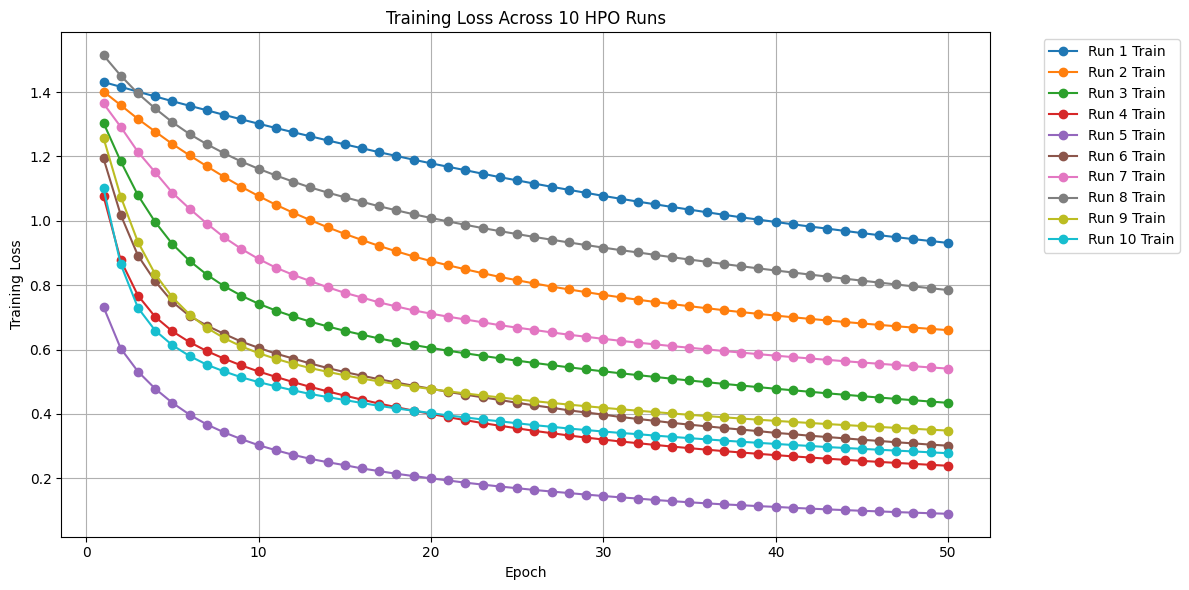

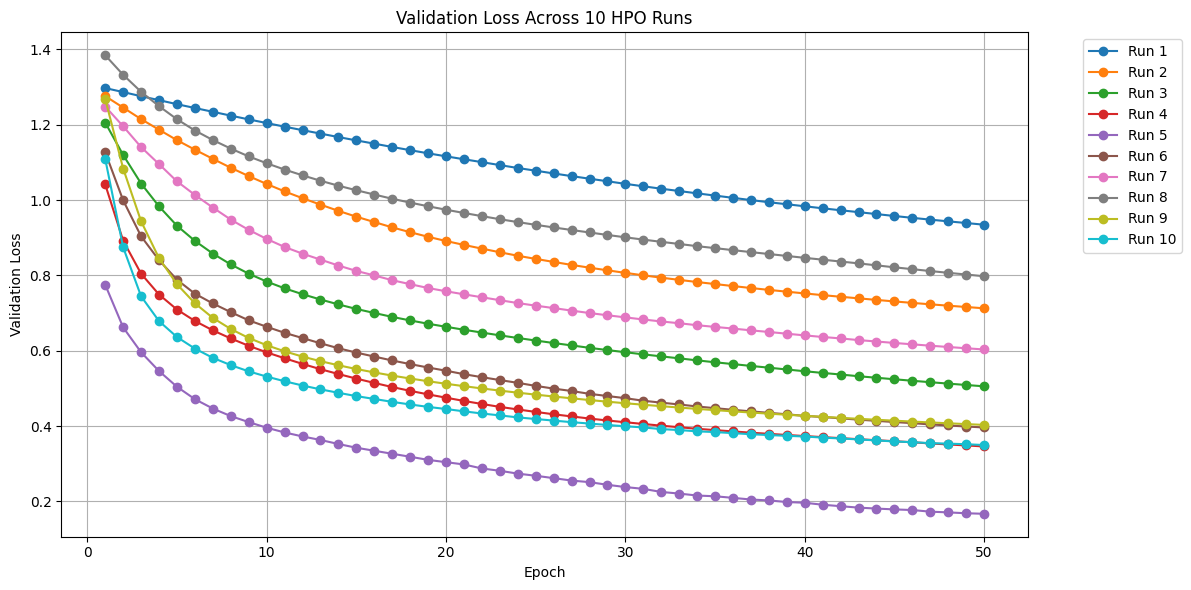

In [ ]:

# CELL 12: PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(12, 6))

for run_id in sorted(epoch_df["run_id"].unique()):

    run_data = epoch_df[
        epoch_df["run_id"] == run_id
    ]

    plt.plot(
        run_data["epoch"],
        run_data["train_loss"],
        marker="o",
        label=f"Run {run_id} Train"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Across 10 HPO Runs")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 6))

for run_id in sorted(epoch_df["run_id"].unique()):

    run_data = epoch_df[
        epoch_df["run_id"] == run_id
    ]

    plt.plot(
        run_data["epoch"],
        run_data["val_loss"],
        marker="o",
        label=f"Run {run_id}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Across 10 HPO Runs")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# CELL 13: CREATE HPO RUN SUMMARY

hpo_summary_records = []

for config in hpo_configs:

    run_id = config["run_id"]

    run_data = epoch_df[
        epoch_df["run_id"] == run_id
    ].sort_values("epoch")

    first_epoch = run_data.iloc[0]
    last_epoch = run_data.iloc[-1]

    record = config.copy()

    record.update({

        "epochs": EPOCHS,
        "random_seed": RANDOM_SEED,

        "initial_train_loss": first_epoch["train_loss"],
        "final_train_loss": last_epoch["train_loss"],

        "initial_val_loss": first_epoch["val_loss"],
        "final_val_loss": last_epoch["val_loss"],

        "final_train_accuracy": last_epoch["train_accuracy"],
        "final_val_accuracy": last_epoch["val_accuracy"],

        "final_val_precision": last_epoch["val_precision"],
        "final_val_recall": last_epoch["val_recall"],
        "final_val_f1": last_epoch["val_f1"]
    })

    hpo_summary_records.append(record)

hpo_runs_df = pd.DataFrame(hpo_summary_records)

# Select using validation loss only
best_run_row = hpo_runs_df.sort_values(
    ["final_val_loss", "final_val_accuracy"],
    ascending=[True, False]
).iloc[0]

best_run_id = int(best_run_row["run_id"])

print("HPO experiment summary:")
display(hpo_runs_df)

print("\nBest validation run:", best_run_id)
print("Best validation loss:", best_run_row["final_val_loss"])


HPO experiment summary:


,run_id,learning_rate,batch_size,hidden_units,optimizer,epochs,random_seed,initial_train_loss,final_train_loss,initial_val_loss,final_val_loss,final_train_accuracy,final_val_accuracy,final_val_precision,final_val_recall,final_val_f1
0,1,0.001,16,8,SGD,50,42,1.430849,0.931254,1.297440,0.934717,0.457143,0.500000,0.428571,0.476190,0.428571
1,2,0.003,16,8,SGD,50,42,1.401315,0.660358,1.276024,0.712847,0.619048,0.681818,0.777778,0.666667,0.600000
2,3,0.010,16,8,SGD,50,42,1.304084,0.434539,1.205864,0.505725,0.857143,0.818182,0.812963,0.809524,0.802614
3,4,0.030,16,8,SGD,50,42,1.076808,0.239138,1.041615,0.346118,0.933333,0.863636,0.861111,0.857143,0.856410
4,5,0.100,16,8,SGD,50,42,0.732357,0.089921,0.775333,0.167342,0.971429,0.909091,0.904762,0.904762,0.904762
5,6,0.010,8,8,SGD,50,42,1.193815,0.301461,1.127096,0.396479,0.914286,0.863636,0.861111,0.857143,0.856410
6,7,0.010,32,8,SGD,50,42,1.364316,0.540910,1.248508,0.603529,0.771429,0.636364,0.422222,0.619048,0.501961
7,8,0.010,16,4,SGD,50,42,1.514139,0.784896,1.384553,0.797925,0.704762,0.818182,0.821429,0.815476,0.815873
8,9,0.010,16,16,SGD,50,42,1.257702,0.348423,1.268375,0.403308,0.895238,0.863636,0.861111,0.857143,0.856410
9,10,0.030,32,16,SGD,50,42,1.100957,0.278129,1.109242,0.349852,0.895238,0.863636,0.861111,0.857143,0.856410



Best validation run: 5
Best validation loss: 0.1673416133036726


In [ ]:

# CELL 14: FINAL TEST EVALUATION

best_params = all_run_models[best_run_id]

test_metrics, test_probabilities, test_cache, test_losses = (
    calculate_metrics(X_test, y_test, best_params)
)

test_predictions = np.argmax(test_probabilities, axis=1)

final_test_df = pd.DataFrame([{
    "selected_run_id": best_run_id,
    "test_loss": test_metrics["loss"],
    "test_accuracy": test_metrics["accuracy"],
    "test_precision": test_metrics["precision"],
    "test_recall": test_metrics["recall"],
    "test_f1": test_metrics["f1"]
}])

print("Final test metrics:")
display(final_test_df)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))


Final test metrics:


,selected_run_id,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,5,0.158296,0.956522,0.962963,0.958333,0.95817



Confusion matrix:
[[7 0 0]
 [0 8 0]
 [0 1 7]]


In [ ]:

# CELL 15: BUILD META-DATASET FEATURES

meta_records = []

for config in hpo_configs:

    run_id = config["run_id"]

    run_data = epoch_df[
        epoch_df["run_id"] == run_id
    ].sort_values("epoch")

    first = run_data.iloc[0]
    last = run_data.iloc[-1]

    # Get initial and final parameter values
    snapshots = parameter_snapshots_df[
        parameter_snapshots_df["run_id"] == run_id
    ]

    initial_params = snapshots[
        snapshots["phase"] == "initial"
    ].sort_values(["parameter_name", "parameter_index"])

    final_params = snapshots[
        (snapshots["phase"] == "epoch_end") &
        (snapshots["epoch"] == EPOCHS)
    ].sort_values(["parameter_name", "parameter_index"])

    initial_values = initial_params["value"].to_numpy()
    final_values = final_params["value"].to_numpy()

    # Calculate total parameter change
    parameter_change_norm = np.linalg.norm(
        final_values - initial_values
    )

    # Construct one meta-dataset row
    record = config.copy()

    record.update({

        "dataset_name": "Iris",
        "dataset_samples": 150,
        "input_features": 4,
        "output_classes": 3,

        "epochs": EPOCHS,
        "random_seed": RANDOM_SEED,

        "activation_function": "ReLU",
        "output_function": "Softmax",
        "loss_function": "CrossEntropy",
        "optimizer": "SGD",

        # Learning curve features
        "initial_train_loss": first["train_loss"],
        "final_train_loss": last["train_loss"],

        "initial_val_loss": first["val_loss"],
        "final_val_loss": last["val_loss"],

        "train_loss_reduction": (
            first["train_loss"] - last["train_loss"]
        ),

        "val_loss_reduction": (
            first["val_loss"] - last["val_loss"]
        ),

        "train_loss_curve": json.dumps(
            run_data["train_loss"].tolist()
        ),

        "val_loss_curve": json.dumps(
            run_data["val_loss"].tolist()
        ),

        "train_accuracy_curve": json.dumps(
            run_data["train_accuracy"].tolist()
        ),

        "val_accuracy_curve": json.dumps(
            run_data["val_accuracy"].tolist()
        ),

        # Final performance
        "final_train_accuracy": last["train_accuracy"],
        "final_val_accuracy": last["val_accuracy"],
        "final_val_precision": last["val_precision"],
        "final_val_recall": last["val_recall"],
        "final_val_f1": last["val_f1"],

        # Weight and bias features
        "initial_weight_norm": first["weight_norm"],
        "final_weight_norm": last["weight_norm"],
        "final_weight_mean": last["weight_mean"],
        "final_weight_std": last["weight_std"],
        "final_bias_mean": last["bias_mean"],
        "final_bias_std": last["bias_std"],

        "parameter_change_norm": parameter_change_norm,

        # Gradient and update features
        "mean_gradient_norm": run_data[
            "gradient_norm_mean"
        ].mean(),

        "final_gradient_norm": last[
            "gradient_norm_mean"
        ],

        "gradient_norm_std": run_data[
            "gradient_norm_mean"
        ].std(),

        "mean_update_norm": run_data[
            "update_norm_mean"
        ].mean(),

        # Training behaviour
        "val_loss_volatility": run_data[
            "val_loss"
        ].std(),

        "train_val_loss_gap": (
            last["val_loss"] - last["train_loss"]
        )
    })

    meta_records.append(record)


meta_dataset_df = pd.DataFrame(meta_records)

print("Meta-dataset successfully constructed!")

print("Number of meta-dataset records:", len(meta_dataset_df))
print("Number of meta-dataset features:", len(meta_dataset_df.columns))

display(meta_dataset_df.head())


Meta-dataset successfully constructed!
Number of meta-dataset records: 10
Number of meta-dataset features: 42


,run_id,learning_rate,batch_size,hidden_units,optimizer,dataset_name,dataset_samples,input_features,output_classes,epochs,...,final_weight_std,final_bias_mean,final_bias_std,parameter_change_norm,mean_gradient_norm,final_gradient_norm,gradient_norm_std,mean_update_norm,val_loss_volatility,train_val_loss_gap
0,1,0.001,16,8,SGD,Iris,150,4,3,50,...,0.489270,0.004153,0.028348,0.419695,1.291606,0.995791,0.179005,0.001292,0.107840,0.003463
1,2,0.003,16,8,SGD,Iris,150,4,3,50,...,0.495081,0.011777,0.050336,0.825474,0.904610,0.536724,0.319840,0.002714,0.157751,0.052489
2,3,0.010,16,8,SGD,Iris,150,4,3,50,...,0.516264,0.019577,0.137733,1.437770,0.559015,0.346673,0.296298,0.005590,0.163583,0.071186
3,4,0.030,16,8,SGD,Iris,150,4,3,50,...,0.565110,0.022106,0.331845,2.427786,0.378960,0.254376,0.222141,0.011369,0.151335,0.106980
4,5,0.100,16,8,SGD,Iris,150,4,3,50,...,0.665218,-0.017424,0.639443,3.998158,0.271386,0.205256,0.153653,0.027139,0.135567,0.077421


In [ ]:

# CELL 16: RECORD FINAL TEST INTERNAL STATES

test_state_records = record_sample_states(
    best_run_id,
    EPOCHS,
    "test",
    X_test,
    y_test,
    test_ids,
    best_params
)

test_states_df = pd.DataFrame(test_state_records)

print("Final test state records:", len(test_states_df))

display(test_states_df.head())


Final test state records: 23


,run_id,epoch,split,sample_id,true_class_id,true_class,predicted_class_id,predicted_class,sample_loss,input_sepal_length,...,hidden_activation_5,hidden_activation_6,hidden_activation_7,hidden_activation_8,output_logit_1,output_logit_2,output_logit_3,output_probability_1,output_probability_2,output_probability_3
0,5,50,test,18,0,setosa,0,setosa,0.003859,-0.201827,...,0.000000,2.747688,0.000000,0.046782,5.167505,-0.452523,-3.158951,0.996148,0.003611,0.000241
1,5,50,test,38,0,setosa,0,setosa,0.001743,-1.715529,...,1.793338,2.846358,0.000000,1.554831,6.352149,-0.009043,-4.609671,0.998258,0.001724,0.000017
2,5,50,test,134,2,virginica,1,versicolor,0.893038,0.263928,...,0.000000,0.000000,0.980097,1.434186,-3.755977,1.513008,1.151738,0.003025,0.587565,0.409410
3,5,50,test,57,1,versicolor,1,versicolor,0.094296,-1.133336,...,1.281601,0.088772,0.000000,2.091594,-0.193223,2.209801,-2.564796,0.082305,0.910013,0.007682
4,5,50,test,127,2,virginica,2,virginica,0.316180,0.263928,...,0.000000,0.000000,1.341252,0.482493,-3.147370,0.906584,1.912979,0.004624,0.266448,0.728928


In [ ]:

# CELL 17: EXPORT RESEARCH DATASETS

output_dir = "ANN_Research_Output"

os.makedirs(output_dir, exist_ok=True)

# Save all datasets
config_df.to_csv(
    f"{output_dir}/hpo_configurations.csv",
    index=False
)

hpo_runs_df.to_csv(
    f"{output_dir}/hpo_runs.csv",
    index=False
)

epoch_df.to_csv(
    f"{output_dir}/epoch_metrics.csv",
    index=False
)

sample_states_df.to_csv(
    f"{output_dir}/sample_states.csv",
    index=False
)

parameter_updates_df.to_csv(
    f"{output_dir}/parameter_updates.csv",
    index=False
)

parameter_snapshots_df.to_csv(
    f"{output_dir}/parameter_snapshots.csv",
    index=False
)

meta_dataset_df.to_csv(
    f"{output_dir}/meta_dataset.csv",
    index=False
)

final_test_df.to_csv(
    f"{output_dir}/final_test_metrics.csv",
    index=False
)

test_states_df.to_csv(
    f"{output_dir}/final_test_states.csv",
    index=False
)

print("All research datasets exported successfully!")


All research datasets exported successfully!


In [ ]:

# CELL 18: CREATE ZIP ARCHIVE
import zipfile
zip_filename = "ANN_Research_Output.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in os.listdir(output_dir):

        file_path = os.path.join(
            output_dir,
            filename
        )

        zip_file.write(
            file_path,
            arcname=filename
        )

print("ZIP archive created:", zip_filename)


ZIP archive created: ANN_Research_Output.zip


In [ ]:

# CELL 19: DOWNLOAD OUTPUT

from google.colab import files

files.download(zip_filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>